# 7.2.2 - Model: Random Forest Lite (lemmatized variant)

**Finding and training the "lite" variant of the Random Forest classifier - with a significantly smaller .joblib file and minimal loss of F1 score compared to the heavy version from `7.1.2`.**

## Motivation

In `7.1.2`, GridSearchCV selected `max_depth=400, min_samples_leaf=2, n_estimators=1500` for the stemmed variant, resulting in a model of **206MB** (F1 = 0.8801).

For the purposes of this work, a file of that size is impractical for storage and sharing, while almost all other models in this work are below 2MB.

The goal of this file is not to find the best possible F1 (that has already been done in `7.1.2`), but to find a reasonable compromise between file size and F1 score, i.e. a "lite" version that:
- targets a file size that does not differ too much from the other `.joblib` files, i.e. not (much) larger than 10MB
- keeps the F1 as close as possible to the heavy version
- is saved separately from the original model, for comparison in `10_evaluation.ipynb`

## Why GridSearchCV from `train_and_evaluate()` is not sufficient here

`train_and_evaluate()` (from `src/modeling.py`) selects hyperparameters exclusively based on F1 score - it has no knowledge of the size of the resulting file.

To find a combination that balances F1 and size, we first have to manually explore the hyperparameter space and measure both for each combination.

Only after selecting the final combination do we call `train_and_evaluate()` with that one (fixed) combination in order to obtain the official, saved model, metrics, and confusion matrix - in the same way as with all other models in this work.

## Hyperparameters

- `n_estimators` - number of trees in the forest
  - More trees → more stable, reliable results (averaging over more "votes")
  - But also slower training - each additional tree increases training time

- `max_depth` - maximum depth of each individual tree in the forest

- `max_features` - how many features are randomly considered at each split
  - `"sqrt"` - considers √66.834 ≈ 258 features per split
  - `"log2"` - considers log₂(66.834) ≈ 17 features per split
  - Fewer features per split means more diverse trees (a lower chance that two trees make the same split), which can improve the ensemble effect

- `min_samples_leaf` - minimum number of samples that a leaf must contain for a split to be allowed
  - A higher value prevents the creation of very small leaves and therefore further regularizes the model

## Which hyperparameters we examine and which we fix

From `7.1.x` we know that `max_features='log2'` performed best (and it intuitively makes sense - fewer features per split means more diverse trees), so we fix it.

We focus on three hyperparameters that directly determine file size:

- `max_depth`:
    - The biggest "driver" of size
    - With 39.665 training examples, a fully balanced tree would theoretically need a depth of only ~15 to separate all examples
    - We expect F1 to increase quickly up to some moderate depth and then slow down, while file size grows almost linearly (deeper trees = more nodes)

- `min_samples_leaf`:
    - In `7.1.2`, 2 was selected, which allows relatively small leaves and contributes to the enormous size
    - We expect larger values to minimally reduce F1 while significantly reducing size

- `n_estimators`:
    - We expect size to grow approximately linearly with the number of trees, while the F1 gain from additional trees quickly diminishes after several hundred/thousand.

<br>

<br>

## Theoretical Background

Random Forest is an ensemble method - instead of training a single tree (as in `6.2`), it trains many independent Decision Tree models and combines their predictions into one final decision in order to obtain a more stable and accurate classifier.

Each tree in the forest is built in a slightly different way than a standard Decision Tree:
- Bootstrap sampling (bagging) - each tree is trained on its own random sample of the TRAIN set, drawn with replacement (the same sample can appear multiple times, while some samples may be completely omitted)
- Random subset of features per split - at each node split, the tree does not consider all features (as a standard Decision Tree does), but only a randomly selected subset (controlled by the `max_features` parameter)
- More trees – the number of trees in the forest is determined by the `n_estimators` parameter (a larger number of trees generally gives more stable results, but increases training time).

The final prediction of the entire forest is a majority vote of all individual trees.

Why this helps:
- An individual tree is unstable - a small change in the training data can produce a completely different tree, and it is prone to overfitting
- By averaging over many different, weakly dependent trees, the errors of individual trees cancel each other out, and the forest as a whole generalizes better to new data

Cost:
- We lose the direct interpretability of an individual tree (now we have many trees instead of one, so we cannot simply "follow" a single sequence of decisions)
- We retain some degree of interpretability through `feature_importances_` (averaged across all trees in the forest, instead of from a single tree as in `6.2`)

## Note on the name `max_features`

`max_features` here is not the same parameter as `max_features` from `3_vectorization.ipynb` (there it controlled the size of the entire TF-IDF vocabulary).

`max_features` here controls how many features are randomly considered at each individual node split within a single tree.

## Processing Flow:

1. We load the previously prepared lemmatized TF-IDF data using the `load_variant()` function

2. Coarse search - we examine a wide range of hyperparameters to get a rough picture of the relationship between F1 and file size

3. Fine search - we examine in more detail the range of hyperparameters that produced the best results in the coarse search

4. Display and selection of the final combination of hyperparameters for which we obtained the best F1-to-file-size ratio

5. We call the shared `train_and_evaluate()` function for the predetermined hyperparameters

6. We analyze `feature_importances_` (averaged across all trees in the forest) to see which terms contribute most to the decisions


In [ ]:
import sys
sys.path.append("..")

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

TMP_MODEL_PATH = Path("../models/_tmp_lite_search.joblib")

## Data Loading

We load the lemmatized variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("lemmatized")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 66834)
Test:  (9917, 66834)


## Helper Function for Measuring F1 and File Size

For each combination of hyperparameters:

1. We estimate F1 using 5-fold cross-validation on the TRAIN set (`cross_val_score`) (the same number of folds as in `train_and_evaluate()`, for comparability and credibility of the F1 values without touching the TEST set)

2. We train the model on the entire TRAIN set (the same thing that happens in the final step) and temporarily save it to disk in order to measure the actual size of the `.joblib` file (the size depends on the structure of the trained trees and cannot be reliably estimated without actually saving the model)

3. We delete the temporary file after measurement (we do not clutter the `models/` folder with intermediate results)

The TEST set is not used at all at this stage of the research - it is reserved for the final evaluation of the selected model, following the same principle used by `train_and_evaluate()`.

`evaluate_combo` - for a given combination of hyperparameters, returns the estimated CV F1 and the size (in MB) of the resulting `.joblib` file trained on the entire TRAIN set.


In [3]:
def evaluate_combo(max_depth, min_samples_leaf, n_estimators, max_features="log2"):
    model = RandomForestClassifier(
        max_depth=max_depth,
        max_features=max_features,
        min_samples_leaf=min_samples_leaf,
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1,
    )

    start = time.time()

    # F1 procena (bez čuvanja modela) kao srednja vrednost od 5-fold cross-validation
    cv_f1 = cross_val_score(model, X_train, y_train, cv=5, scoring="f1", n_jobs=-1).mean()

    # Trening na celom TRAIN skupu, radi merenja stvarne veličine fajla
    model.fit(X_train, y_train)
    joblib.dump(model, TMP_MODEL_PATH)
    size_mb = TMP_MODEL_PATH.stat().st_size / (1024 ** 2)
    TMP_MODEL_PATH.unlink()                                 # brišemo privremeni fajl

    elapsed = time.time() - start

    return {
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "n_estimators": n_estimators,
        "f1": cv_f1,
        "size_mb": size_mb,
        "time_s": elapsed,
    }

## Step 1: Coarse Search

We examine a wide range of `max_depth` values, combined with `min_samples_leaf` and `n_estimators`, to get a rough picture of the relationship between F1 and file size before focusing on a narrower region.


In [4]:
coarse_max_depth = [10, 50, 200, 500]
coarse_min_samples_leaf = [2, 3]
coarse_n_estimators = [1000, 1500, 2000]

coarse_results = []
for depth in coarse_max_depth:
    for leaf in coarse_min_samples_leaf:
        for n_est in coarse_n_estimators:
            result = evaluate_combo(depth, leaf, n_est)
            coarse_results.append(result)

coarse_df = pd.DataFrame(coarse_results)

coarse_df.style.format({"f1": "{:.4f}", "size_mb": "{:.1f}", "time_s": "{:.0f}"})

,max_depth,min_samples_leaf,n_estimators,f1,size_mb,time_s
0,10,2,1000,0.8471,3.4,56
1,10,2,1500,0.8503,5.1,59
2,10,2,2000,0.8518,6.8,46
3,10,3,1000,0.8471,2.9,33
4,10,3,1500,0.8498,4.3,45
5,10,3,2000,0.8510,5.7,47
6,50,2,1000,0.8711,25.0,46
7,50,2,1500,0.8725,37.6,72
8,50,2,2000,0.8733,50.3,89
9,50,3,1000,0.8701,17.0,41


## Comment on the Coarse Search

The results confirm the expected trade-off between F1 score and model size and support the assumptions from the introduction:

- `max_depth`
    - **The dominant factor determining model size, with clearly diminishing returns on F1**
    - The results confirm the main hypotheses from the introduction and clearly demonstrate the trade-off between F1 score and model size
    - Average F1 increases from: 0.8495 (10) -> 0.8721 (50) -> 0.8780 (200) -> 0.8793 (500)
    - Average size increases from: 4.70 MB (10) -> 31.55 MB (50) -> 118.13 MB (200) -> 163.55 MB (500)
    - From 10 to 50, F1 increases by ~0.023 for a ~6.7x larger file -> a relatively good trade-off if model size is not strictly limited
    - From 50 to 500, F1 increases by only ~0.007 for a file that is ~5.2x larger -> a significantly smaller gain in F1 relative to the additional model size

- `min_samples_leaf`
    - **2 vs. 3 has a negligible effect on F1, but a noticeable effect on size**
    - For `min_samples_leaf=2`, the average F1 is around 0.8700, while the average size is around 99.90 MB
    - For `min_samples_leaf=3`, the average F1 is around 0.8694, while the average size drops to around 59.07 MB
    - Moving from `leaf=2` to `leaf=3` results in a loss of only around 0.0006 F1, while reducing model size by around 41%
    - The effect is particularly pronounced at greater depths (for `max_depth=500` and `n_estimators=1000`, a loss of 0.0009 F1 results in a model size reduction of around 44%)
    - This represents a useful way to regularize and reduce model size
    - The fine search should also test values greater than 3

- `n_estimators`
    - **Model size and training time grow approximately linearly, while the gain in F1 quickly diminishes**
    - In most tested combinations, increasing from 1000 to 1500 trees provides a small improvement in F1
    - Increasing from 1500 to 2000 generally provides an even smaller gain or even a slight decrease in F1
    - Therefore, after approximately 1000-1500 trees, additional trees generally provide very little gain, while still significantly increasing file size and training time

Based on the coarse search:
- `max_depth` appears to be the most important parameter for finding a lite model, because it directly controls how complex individual trees can be and therefore how many nodes, and consequently how much data, the model needs to store.
- `min_samples_leaf` appears to be a useful additional mechanism for reducing size with relatively little loss in F1
- `n_estimators` should be kept at moderately high values because after a certain number of trees, the gain in F1 quickly diminishes.

None of the combinations from the coarse search come close to our target size (~10MB) with a satisfactory F1.

There is a large gap between `max_depth=10` (average ~4.70MB) and `max_depth=50` (average ~31.55MB) where a better trade-off is likely to be found.

We examine this region with a finer search.


## Step 2: Fine Search Around the Target Values

We zoom in on `max_depth` between 10 and 50 (values 15, 20, 25, 30, 35, 40)

We expand `min_samples_leaf` with values above 3

We limit `n_estimators` to between 1000 and 1500 - in the coarse step, going above that was rarely worthwhile at smaller depths.


In [5]:
fine_max_depth = [15, 20, 25, 30, 35, 40]
fine_min_samples_leaf = [2, 3, 4, 5]
fine_n_estimators = [1000, 1250, 1500]

fine_results = []
for depth in fine_max_depth:
    for leaf in fine_min_samples_leaf:
        for n_est in fine_n_estimators:
            result = evaluate_combo(depth, leaf, n_est)
            fine_results.append(result)

fine_df = pd.DataFrame(fine_results)
all_results_df = pd.concat([coarse_df, fine_df], ignore_index=True)

## Pareto Analysis: Selecting the Final Combination

From all tested combinations (coarse + fine), we identify those that are Pareto-optimal around the target size.

In other words, there is no other combination that is simultaneously smaller and better than them.


In [6]:
sorted_df = all_results_df.sort_values("size_mb").reset_index(drop=True)

pareto_rows = []
best_f1_so_far = -np.inf

for _, row in sorted_df.iterrows():
    if row["f1"] > best_f1_so_far:
        pareto_rows.append(row)
        best_f1_so_far = row["f1"]

pareto_df = pd.DataFrame(pareto_rows).reset_index(drop=True)
pareto_df[["max_depth", "min_samples_leaf", "n_estimators", "f1", "size_mb"]].style.format({"max_depth": "{:.0f}", "min_samples_leaf": "{:.0f}", "n_estimators": "{:.0f}", "f1": "{:.4f}", "size_mb": "{:.1f}"})

,max_depth,min_samples_leaf,n_estimators,f1,size_mb
0,10,3,1000,0.8471,2.9
1,15,5,1000,0.8579,3.6
2,15,4,1000,0.8583,3.8
3,15,3,1000,0.8584,4.4
4,15,5,1250,0.8590,4.5
5,20,5,1000,0.8629,4.7
6,20,5,1250,0.8637,5.9
7,25,5,1000,0.8653,6.0
8,30,5,1000,0.8678,7.2
9,35,5,1000,0.8684,8.4


## Visual Reprezentation


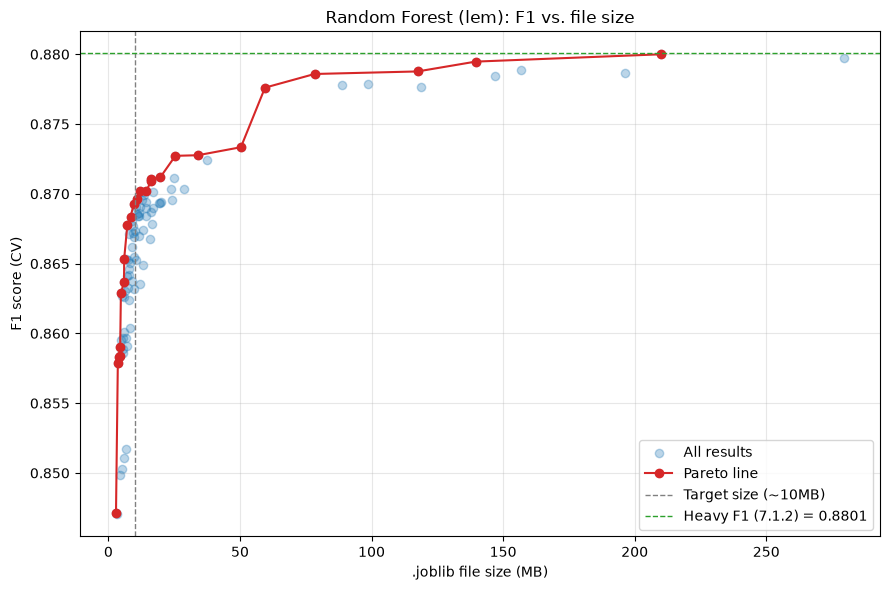

In [7]:
plt.figure(figsize=(9, 6))
plt.scatter(all_results_df["size_mb"], all_results_df["f1"], alpha=0.3, label="All results")
plt.plot(pareto_df["size_mb"], pareto_df["f1"], marker="o", color="tab:red", label="Pareto line")

plt.axvline(10, color="gray", linestyle="--", linewidth=1, label="Target size (~10MB)")
plt.axhline(0.8801, color="tab:green", linestyle="--", linewidth=1, label="Heavy F1 (7.1.2) = 0.8801")

plt.xlabel(".joblib file size (MB)")
plt.ylabel("F1 score (CV)")
plt.title("Random Forest (lem): F1 vs. file size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final Combination Selection

We select `max_depth=40, min_samples_leaf=5, n_estimators=1000, max_features='log2'`:

- The size (9.7MB) is close to the target value of ~10MB, with very little room below the limit

- It lies on the Pareto front and represents a better F1/size trade-off than its neighboring points on the front:
    - The previous point (`max_depth=35, min_samples_leaf=5, n_estimators=1000`) is smaller (8.4MB) but gives an F1 that is 0.0009 lower - the step to 40/5/1000 provides a better F1/size trade-off (+0.0009 F1 for only +15% in size) than what would be saved by taking the step backward, so it is worthwhile
    - The next point (`max_depth=40, min_samples_leaf=4, n_estimators=1000`) gives only +0.0003 F1 for an additional 11% larger file (10.8MB) - a weak trade-off, so it is not worthwhile

- The F1 vs. file size plot shows that a significantly better point exists only at ~59.5MB (`max_depth=200, min_samples_leaf=3, n_estimators=1000`, F1 0.8776) - but that would exceed the target size by ~6x, so we stay with the smaller, targeted model

- The same combination as in the `lanc` variant (`7.2.3`), including the identical file size (9.7MB) - this confirms the earlier observation that the lemmatized and Lancaster-stemmed variants (both of which group words more aggressively/differently than Porter stemming) consistently reach their optimum at `max_depth=40`

- Unlike the `stem` and `base` variants, where the optimal combination was `max_depth=35`, here `max_depth=40` is slightly better - showing that the assumption of an identical optimal combination across all variants does not fully hold, although the difference is small

- Compared to the heavy version (F1-0.8801, size-202MB), we expect a loss of ~0.011 F1 (around 1.2%) for a file that is ~20x smaller

Note:
- The F1 above is an estimate obtained through cross-validation on the TRAIN set
- Final evaluation on the TEST set, which we have not used so far, is performed only now, through `train_and_evaluate()` from `src/modeling.py`


========== lite_random_forest (lem) ==========
Best parameters: {'max_depth': 40, 'max_features': 'log2', 'min_samples_leaf': 5, 'n_estimators': 1000}
GridSearchCV time: 27.4s

Accuracy  : 0.8592
Precision : 0.8263
Recall    : 0.9110
F1        : 0.8666


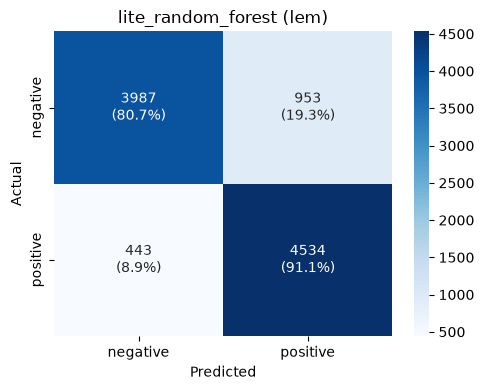


Saved:
  ..\models\lite_random_forest_lem.joblib
  ..\results\metrics\lite_random_forest_lem.json
  ..\results\figures\lite_random_forest_lem_confusion_matrix.png


In [8]:
model = RandomForestClassifier(random_state=1)

param_grid = {
    "n_estimators": [1000],
    "max_depth": [40],
    "max_features": ["log2"],
    "min_samples_leaf": [5],
}

metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="lite_random_forest",
    variant="lem",
)

## Feature Importance - Comparison with the Heavy Version

`feature_importances_` represents a measure of feature importance.

The value indicates how much a particular term contributed to reducing "impurity" across all splits.

A higher value means that the feature made a greater contribution to reducing impurity at the splits in the Random Forest model's trees.

The same principle as in `7.1.2` - `feature_importances_` averaged across all trees.

We expect the lite version, with significantly fewer trees (1000 vs 1500) and shallower trees (max_depth=40 vs 400), to use a smaller portion of the vocabulary than the heavy version (which used 100% of the terms) - leaving less room for "rare", specific terms to obtain non-zero importance.


In [9]:
best_model = joblib.load("../models/lite_random_forest_lem.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_lem.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
importances = best_model.feature_importances_

top_idx = np.argsort(importances)[-20:][::-1]

print("Top 20 most influential terms (lite):")
for idx in top_idx:
    print(f"  {feature_names[idx]:30s}  {importances[idx]:.4f}")

n_zero_importance = np.sum(importances == 0)
print(f"\nNumber of terms that the forest never used for splitting: {n_zero_importance} out of {len(importances)} ({n_zero_importance / len(importances):.1%})")

Top 20 most influential terms (lite):
  great                           0.0070
  bad                             0.0055
  waste                           0.0050
  best                            0.0049
  no                              0.0046
  wonderful                       0.0044
  bad movie                       0.0044
  terrible                        0.0039
  not                             0.0039
  awful                           0.0039
  stupid                          0.0036
  not even                        0.0035
  excellent                       0.0035
  waste time                      0.0033
  poor                            0.0031
  money                           0.0026
  ridiculous                      0.0026
  dull                            0.0026
  one best                        0.0025
  performance                     0.0025

Number of terms that the forest never used for splitting: 47778 out of 66834 (71.5%)


## Conclusions

- Instead of the standard `GridSearchCV` (which selects hyperparameters exclusively based on F1 score), the light version was found through a targeted search that measured both F1 and the actual `.joblib` file size for each combination - coarse search followed by fine search, and then Pareto analysis

- The F1 vs. file size plot revealed that the curve is not smooth: after ~14MB, a long plateau appears (up to ~59MB) where additional size contributes relatively little to F1, and only at ~59.5MB does a real jump occur (F1 0.8776).
Since the goal was to stay close to ~10MB, this jump was not utilized, but it is worth mentioning as a finding that would be interesting if the size limit were not a priority

- Selected final combination: `max_depth=40, min_samples_leaf=5, n_estimators=1000, max_features='log2'` - identical to the combination used for the `lanc` variant (`7.2.3`), unlike `stem`/`base`, where the optimum was `max_depth=35`. This confirms the earlier observation: the lemmatized and Lancaster-stemmed variants consistently reach their optimum at `max_depth=40`, while the less aggressively reduced variants (`stem`, `base`) reach their optimum at `max_depth=35`

- Final results on the TEST set (`lite_random_forest`, lem):
  - Accuracy  : 0.8592
  - Precision : 0.8263
  - Recall    : 0.9110
  - F1        : 0.8666
  - Saved file size: 9.6 MB

- Test F1 (0.8666) is somewhat lower than the CV estimate from the search (0.8693, difference 0.0027) - a larger difference than for the `stem` (0.0007) and `base` (0.0013) variants, but still within reasonable bounds

- Compared to the heavy version (`7.1.2`: F1-0.8801, size-202MB), the light version loses 0.0135 F1 (~1.53%), with a file that is ~21x smaller

- Recall (0.9110) is significantly higher than precision (0.8263) - meaning that the model successfully identifies the majority of positive reviews (91.1% correctly identified), with somewhat more false positives (the negative class is correctly identified in 80.7% of cases).
The same asymmetry exists in the heavy version (recall 0.9019 > precision 0.8593), although it is slightly more pronounced here - a consistent pattern across all light models

- Feature importance: the light version used only 28.5% of the vocabulary for splits (47.778 out of 66.834 terms were never used), compared to 94.2% for the heavy version (only 5.8% unused) - a direct consequence of the smaller depth (40 vs. 400) and fewer trees (1000 vs. 1500). The difference in vocabulary utilization is less drastic here than with `stem` (100% vs. 26.8%), since the heavy `lem` model is also relatively moderate in size (202MB, not 6.4GB)

- The core of the most influential terms is largely identical to the heavy version (bad, waste, great, "bad movie", awful, terrible, "not even", no, "waste time", not, wonderful, excellent, best, "one best", poor, stupid - they appear in the top 20 of both models), confirming that the light model, although much smaller, relies on the same robust sentiment signals

- Several terms appear only in the heavy version (love, nothing, horrible, minute), while the light version introduces its own semantically meaningful terms (money, ridiculous, dull, performance) - the difference is considerably milder than with `stem`, where the light model showed a more pronounced redistribution toward a narrower set of terms

<br>

Overall conclusion: the cost of ~1.53% F1 for a ~21x smaller file represents a favorable trade-off - the light version is practically usable while retaining most of the predictive power of the heavy model.
